# 04 - Real loop analysis (CPU): losslessness, wall-clock, simulator vs real
Input: `data/real_loop/` (unzipped `real_loop.zip` from Kaggle notebook 03) and `data/traces_v2/timing.json` (cost model from notebook 01). Policy parameters are read from the real run's `run_info.json`, i.e. exactly what ran.
Outputs: `results/phase1/real_loop.csv`, `real_loop_lossless.csv`, `real_loop_cost_model.csv`, `sim_vs_real.csv`, `real_loop_ci.csv`, `sim_vs_real_decomposition.csv`, `real_loop_after_mismatch.csv`, `plot_sim_vs_real.png`.

In [1]:
import json, os
from pathlib import Path
import numpy as np, pandas as pd
from lgmtp.gpu_traces import read_jsonl, load_tokenizer
from lgmtp.traces import load_traces
from lgmtp.vocab import build_masks
from lgmtp.policies import TokenTable
from lgmtp.morph import PrefixBoundaryModel
from lgmtp.simulator import load_timing, make_verify, simulate, summarize
from lgmtp.tuning import Context, make_policy, cap_for
from lgmtp import analysis

RL = Path(os.environ.get('LGMTP_REAL', '../data/real_loop'))
TIMING = Path(os.environ.get('LGMTP_TIMING', '../data/traces_v2/timing.json'))
PREFIX = Path(os.environ.get('LGMTP_PREFIX', '../results/phase1/prefix_model.pkl.gz'))
RES = Path(os.environ.get('LGMTP_RES', '../results/phase1')); RES.mkdir(parents=True, exist_ok=True)
info = json.loads((RL / 'run_info.json').read_text(encoding='utf-8'))
results = read_jsonl(RL / 'loop_results.jsonl')
refs = {r['id']: r for r in read_jsonl(RL / 'greedy_unbatched.jsonl')}
traces, tmeta = load_traces(RL / 'traces_real100.npz')
T = load_timing(TIMING); C_RATIO = T['c']; VERIFY = make_verify(T)
print(len(results), 'decodes |', info['n_sent'], 'sentences x', info['repeats'], 'repeats | policies', info['policies'])

1800 decodes | 100 sentences x 3 repeats | policies ['NoDraft', 'FixedK', 'Entropy', 'WordBoundarySoft', 'Hybrid', 'MorphEntropy_ext1']


## 1. Losslessness (vs unbatched greedy target output)

In [2]:
div = json.loads((RL / 'divergences.json').read_text())
ll = pd.DataFrame([dict(policy=r['policy'], rep=r['rep'], id=r['id'], lossless=r['lossless']) for r in results])
lt = ll.groupby('policy').lossless.agg(['sum', 'size']).rename(columns={'sum': 'identical', 'size': 'decodes'}).reset_index()
lt.to_csv(RES / 'real_loop_lossless.csv', index=False); print(lt.to_string())
if div:
    d = pd.DataFrame(div); d.to_csv(RES / 'real_loop_divergences.csv', index=False)
    print(d.to_string()); print('max |margin| at divergences:', d.margin.abs().max())
else:
    print('no divergences')

              policy  identical  decodes
0            Entropy        285      300
1             FixedK        285      300
2             Hybrid        288      300
3  MorphEntropy_ext1        288      300
4            NoDraft        288      300
5   WordBoundarySoft        285      300
     id             policy  pos  ref_token  loop_token    top1    top2    margin
0     2            NoDraft   95      92317      101541  101541   92317  0.015625
1     2             FixedK   95      92317      101541  101541   92317  0.015625
2     2            Entropy   95      92317      101541  101541   92317  0.015625
3     2   WordBoundarySoft   95      92317      101541  101541   92317  0.015625
4     2             Hybrid   95      92317      101541  101541   92317  0.015625
5     2  MorphEntropy_ext1   95      92317      101541  101541   92317  0.015625
6    31            Entropy   74     100443      102341  102341  100443  0.000000
7    31             Hybrid   74     100443      102341  102341  1

## 2. Wall-clock (median over repeats, warm-up excluded)

In [3]:
real = analysis.real_loop_tables(results)
real.to_csv(RES / 'real_loop.csv', index=False)
real.round(4)

,policy,params,sentences,tokens,wall_s,tokens_per_s,speedup_wall,tokens_per_verif,mean_draft_len,acceptance_rate,lossless_rate,n_lossless,n_decodes,extra_lookahead_rounds
0,Entropy,"{""lam"": -0.683, ""beta"": 4.0}",100,6652,344.3305,19.3186,1.3560,2.4420,2.2562,0.7130,0.95,285,300,0
1,FixedK,"{""k"": 2}",100,6677,357.9419,18.6539,1.3044,2.2466,2.0000,0.6487,0.95,285,300,0
2,Hybrid,"{""lam"": -0.621, ""beta"": 2.0, ""tau_w"": 0.2, ""ma...",100,6675,407.6863,16.3729,1.1453,2.7941,3.2152,0.6187,0.96,288,300,2066
3,MorphEntropy_ext1,"{""lam"": -0.621, ""beta"": 4.0, ""tau_morph"": 0.1,...",100,6653,353.0149,18.8462,1.3226,2.6100,2.7234,0.6592,0.96,288,300,0
4,NoDraft,{},100,6649,466.9133,14.2403,1.0000,1.0000,0.0000,0.0000,0.96,288,300,0
5,WordBoundarySoft,"{""tau"": 0.05, ""min_g"": 2}",100,6675,425.9107,15.6723,1.0963,2.6425,3.0344,0.5810,0.95,285,300,2522


## 3. Cost model check: measured time per round vs `g*t_draft` and `verify(g)*t_target`

In [4]:
cm = analysis.cost_model_table(results, T['t_draft'], T['t_target'], VERIFY)
cm.to_csv(RES / 'real_loop_cost_model.csv', index=False)
cm.round(3)

,g,rounds,t_draft_ms,t_verify_ms,frac_extra,model_t_draft_ms,model_t_verify_ms
0,0,19947,0.013,68.410,0.000,0.000,70.589
1,1,9219,29.240,71.565,0.299,29.638,71.969
2,2,17106,50.353,71.846,0.241,51.111,72.373
3,3,5247,81.470,72.693,0.623,82.644,72.974
4,4,2874,104.312,73.100,0.636,105.738,73.611
5,5,1590,125.918,73.401,0.604,127.819,74.816
6,6,1170,144.588,73.494,0.446,147.034,75.027
7,7,696,166.927,73.972,0.440,169.695,75.224
8,8,1578,179.403,74.732,0.000,182.476,75.796


## 4. Simulator vs real
Simulator on teacher-forced traces of the same 100 unbatched greedy outputs, same params and cost model. Relative errors > 5% are flagged; explanations to consider: teacher-forcing approximation (stopping after a mismatch), lookahead cost (charged vs uncharged bounds), cache / Python overhead in the real loop, the end-of-sentence cap (simulator caps at n - p, the live loop at max_new - p), and `c` measured separately in notebook 01.

In [5]:
tok = load_tokenizer('meta-llama/Llama-3.2-1B-Instruct')
masks = build_masks(tok, tmeta['eos_ids'])
ctx = Context(newword_mask=masks.starts_newword, prefix_model=PrefixBoundaryModel.load(PREFIX),
              table=TokenTable.from_tokenizer(tok, masks))
assert [t.id for t in traces] == list(refs)[:len(traces)] or set(t.id for t in traces) <= set(refs)
sim_rows = []
for fam in info['policies']:
    params = info['selected'].get(fam, {})
    pol = make_policy(fam, params, ctx); cap = cap_for(fam, params)
    ch = summarize(simulate(traces, pol, cap, C_RATIO, VERIFY, charge_lookahead=True, record_rounds=False))
    un = summarize(simulate(traces, pol, cap, C_RATIO, VERIFY, charge_lookahead=False, record_rounds=False))
    sim_rows.append(dict(policy=fam, tokens_per_verif=ch['tokens_per_verif'], mean_draft_len=ch['mean_draft_len'],
                         speedup_sim_charged=ch['speedup'], speedup_sim_uncharged=un['speedup']))
svr = analysis.sim_vs_real(real, sim_rows)
svr.to_csv(RES / 'sim_vs_real.csv', index=False)
cols = ['policy', 'tokens_per_verif_real', 'tokens_per_verif_sim', 'mean_draft_len_real', 'mean_draft_len_sim',
        'speedup_wall', 'speedup_sim_charged', 'speedup_sim_uncharged'] + [c for c in svr.columns if c.startswith('relerr_')] + ['flag_gt_5pct']
svr[cols].round(4)

Linguistically-guided-MTP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,policy,tokens_per_verif_real,tokens_per_verif_sim,mean_draft_len_real,mean_draft_len_sim,speedup_wall,speedup_sim_charged,speedup_sim_uncharged,relerr_tokens_per_verif,relerr_mean_draft_len,relerr_speedup_charged,relerr_speedup_uncharged,flag_gt_5pct
0,Entropy,2.4420,2.4517,2.2562,2.0878,1.3560,1.4400,1.4400,0.0040,-0.0746,0.0619,0.0619,True
1,FixedK,2.2466,2.2476,2.0000,1.9761,1.3044,1.3510,1.3510,0.0004,-0.0120,0.0357,0.0357,False
2,Hybrid,2.7941,2.8041,3.2152,2.9344,1.1453,1.2424,1.4141,0.0036,-0.0873,0.0848,0.2347,True
3,MorphEntropy_ext1,2.6100,2.6120,2.7234,2.5188,1.3226,1.4157,1.4157,0.0007,-0.0751,0.0704,0.0704,True
4,NoDraft,1.0000,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,0.0000,NaN,0.0000,0.0000,False
5,WordBoundarySoft,2.6425,2.6462,3.0344,2.9572,1.0963,1.1514,1.3299,0.0014,-0.0255,0.0503,0.2131,True


## 5. Real wall-clock speed-up with sentence-bootstrap CIs
Ratio of sums of per-sentence medians (over repeats) vs NoDraft; paired bootstrap difference to Entropy.

In [6]:
NBOOT = int(os.environ.get('LGMTP_NBOOT', 1000))
ci = analysis.real_speedup_ci(results, T, ref='Entropy', n_boot=NBOOT)
ci.to_csv(RES / 'real_loop_ci.csv', index=False)
(RES / 'real_loop_run_info.json').write_text(json.dumps(info, indent=1, ensure_ascii=False), encoding='utf-8')
ci.round(4)

,policy,speedup_wall,lo,hi,diff_vs_ref,diff_lo,diff_hi,p_better_than_ref
0,Entropy,1.3560,1.3281,1.3809,NaN,NaN,NaN,NaN
1,MorphEntropy_ext1,1.3226,1.2954,1.3488,-0.0334,-0.0444,-0.0225,0.0
2,FixedK,1.3044,1.2798,1.3278,-0.0516,-0.0684,-0.0351,0.0
3,Hybrid,1.1453,1.1148,1.1746,-0.2107,-0.2249,-0.1973,0.0
4,WordBoundarySoft,1.0963,1.0708,1.1220,-0.2597,-0.2788,-0.2393,0.0
5,NoDraft,1.0000,1.0000,1.0000,-0.3560,-0.3809,-0.3281,0.0


## 6. Where does the simulator-vs-real gap come from?
sim (teacher-forced rounds + cost model) -> real rounds capped at the end of the sentence + cost model (teacher-forcing approximation) -> real rounds as run + cost model (the live loop caps the draft at max_new - p, not n - p, so in the round that commits the end-of-sentence token it keeps drafting past it) -> real rounds + measured forward times (cost-model error) -> wall clock (per-round overhead outside the forwards).

In [7]:
gap = analysis.gap_decomposition(results, T, {r['policy']: r['speedup_sim_charged'] for r in sim_rows})
gap.to_csv(RES / 'sim_vs_real_decomposition.csv', index=False)
gap.round(4)

,policy,speedup_sim,speedup_real_rounds_capped_model,speedup_real_rounds_model,speedup_real_rounds_measured,speedup_wall,eos_overrun_tokens_per_sentence,step_teacher_forcing,step_eos_overrun,step_cost_model,step_overhead,total,overhead_share_of_wall
0,Entropy,1.4400,1.4357,1.3882,1.3700,1.3560,4.78,-0.0030,-0.0331,-0.0131,-0.0102,-0.0583,0.0359
1,FixedK,1.3510,1.3447,1.3384,1.3166,1.3044,0.71,-0.0046,-0.0047,-0.0163,-0.0092,-0.0345,0.0349
2,Hybrid,1.2424,1.2252,1.1817,1.1520,1.1453,6.04,-0.0138,-0.0355,-0.0251,-0.0059,-0.0782,0.0316
3,MorphEntropy_ext1,1.4157,1.4134,1.3638,1.3363,1.3226,5.17,-0.0017,-0.0351,-0.0201,-0.0102,-0.0658,0.0359
4,NoDraft,1.0000,1.0000,1.0000,1.0000,1.0000,0.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0259
5,WordBoundarySoft,1.1514,1.1453,1.1258,1.1000,1.0963,3.03,-0.0052,-0.0171,-0.0229,-0.0034,-0.0479,0.0292


## 7. Drafting after a mismatch: real loop vs teacher-forced simulator
In the real loop the draft keeps conditioning on its own (wrong) token; on teacher-forced traces it sees the target's token. If real drafts run longer *after* the first mismatch, the real loop pays more draft cost for the same accepted tokens.

In [8]:
sim_recs = {}
for fam in info['policies']:
    if fam == 'NoDraft':
        continue
    params = info['selected'].get(fam, {})
    sim_recs[fam] = simulate(traces, make_policy(fam, params, ctx), cap_for(fam, params), C_RATIO, VERIFY,
                             charge_lookahead=True, record_rounds=True).records
dm = analysis.drafting_after_mismatch(results, sim_recs)
dm.to_csv(RES / 'real_loop_after_mismatch.csv', index=False)
dm.round(3)

,policy,source,rounds,frac_rejected,mean_g_full,mean_g_rejected,mean_after_mismatch
0,FixedK,real,2972,0.434,1.958,2.000,0.619
1,FixedK,sim,2968,0.433,1.958,2.000,0.619
2,Entropy,real,2724,0.486,2.053,2.110,0.246
3,Entropy,sim,2721,0.488,2.056,2.121,0.236
4,WordBoundarySoft,real,2526,0.496,2.717,3.115,1.502
5,WordBoundarySoft,sim,2521,0.495,2.720,3.199,1.584
6,Hybrid,real,2389,0.606,2.724,3.117,0.863
7,Hybrid,sim,2379,0.605,2.723,3.072,0.801
8,MorphEntropy_ext1,real,2549,0.529,2.420,2.610,0.656
9,MorphEntropy_ext1,sim,2554,0.531,2.411,2.614,0.643


## 8. Plot

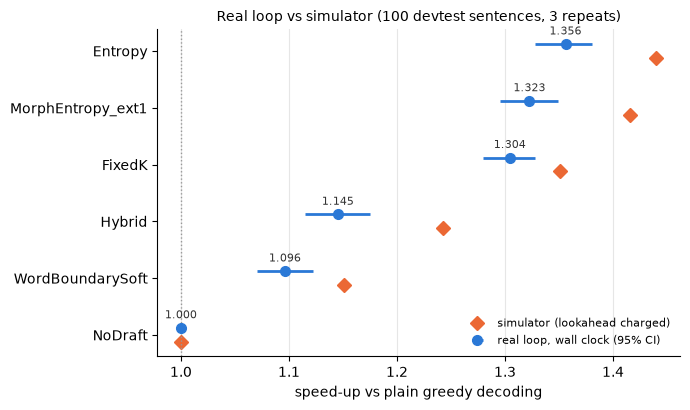

In [9]:
fig = analysis.plot_sim_vs_real(ci, pd.DataFrame(sim_rows), RES / 'plot_sim_vs_real.png')